# Margin and Total Distributions

The probability of any final home margin or combined score, for every regular-season game, using only information available before tip-off.

| Target | Prediction | Distribution |
|---|---|---|
| Home margin | Ridge regression on every feature of the game outcome model ([09_game_outcomes](09_game_outcomes.ipynb)) | Normal, in one-point bins with no ties (games go to overtime), each final margin up to 25 points reweighted so expected and actual counts match on the training seasons (smoothed over neighboring margins). The weights and the normal's SD are fit in turn, the SD by maximum likelihood on the last two training seasons |
| Total | Expected total from the teams' pre-game ratings: average pace x (each offense's rating + the opposing defense's rating) / 200, plus a ridge regression on what that misses | Normal, SD of the residuals over the last two training seasons |

**Total features:** pace, offensive, defensive and Four Factors rates of both teams relative to the league average that day (every team's latest pre-game value), home court, games played, rest days, back-to-backs, arena altitude and talent lost to absences. Rates are season to date blended with last season, as in the game outcome model. Predicting the gap to the expected total, with league-relative rates, keeps a model trained on lower-scoring seasons from carrying their scoring level forward.

**Evaluation:** walk-forward, each season from 2015-16 to 2025-26 predicted by models fit on every season from 2013-14 up to the one before it. Over probabilities are checked on half-point lines set from 15 points below to 15 points above each game's prediction.

Source: Basketball-Reference (team and player game logs, box scores).

In [1]:
import pandas as pd
import plotly.io as pio

from nba_analytics.teams import games, totals
from nba_analytics.teams.totals_plots import (plot_game, plot_line_calibration,
                                              plot_margin_shape, plot_scoring_by_season,
                                              plot_total_pit)

# Interactive in JupyterLab / VS Code; static PNG fallback where Plotly can't run (e.g. GitHub)
pio.renderers.default = "plotly_mimetype+png"
pio.renderers["png"].scale = 0.7
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 30)

FIRST_TEST, LAST_TEST = 2016, 2026
df = totals.total_features(games.game_dataset(2014, 2026))

## Scoring by season

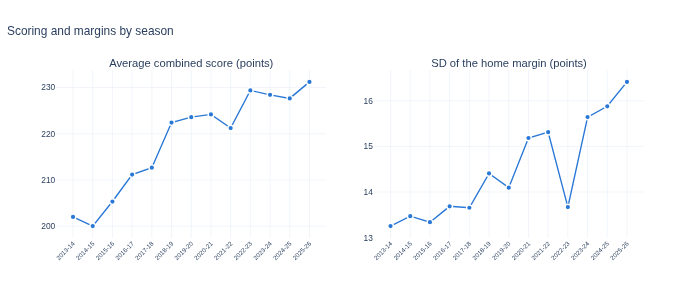

In [2]:
plot_scoring_by_season(df).show()

## Accuracy

Bias is actual minus predicted; SD is the spread of the distribution used (for the margin, the SD of the normal before the close-game weights).

In [3]:
preds, weights = totals.walk_forward(df, FIRST_TEST, LAST_TEST)
totals.scores(preds).round(3)

,target,n,mae,bias,rmse,sd
0,margin,13209,10.274,-0.195,13.147,13.174
1,total,13209,14.824,0.116,18.740,18.473


In [4]:
totals.scores(preds, by_season=True).round(2)

,target,season,n,mae,bias,rmse,sd
0,margin,2016,1230,9.26,0.08,11.71,11.79
1,margin,2017,1230,9.87,0.56,12.46,11.74
2,margin,2018,1230,9.79,-0.53,12.55,12.13
3,margin,2019,1230,9.99,0.23,12.87,12.74
4,margin,2020,1059,9.98,0.03,12.78,13.00
5,margin,2021,1080,10.86,-1.43,13.84,13.21
6,margin,2022,1230,10.86,-0.64,13.88,13.90
7,margin,2023,1230,9.89,0.16,12.57,14.69
8,margin,2024,1230,10.73,-0.01,13.78,13.71
9,margin,2025,1230,10.69,-0.41,13.75,13.57


## How games end

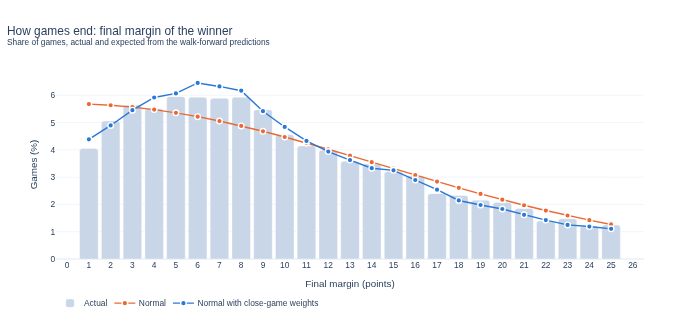

In [5]:
plot_margin_shape(totals.margin_shape(preds, weights)).show()

Close-game weights by final margin, as fit for 2025-26, relative to margins over 25 points (weight 1).

In [6]:
pd.DataFrame({"margin": range(1, totals.CLOSE_MARGIN + 1),
              "weight": weights[LAST_TEST][1:].round(3)}).set_index("margin").T

margin,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25
weight,1.076,1.202,1.334,1.442,1.507,1.601,1.632,1.637,1.529,1.412,1.32,1.263,1.239,1.206,1.223,1.14,1.077,1.003,1.022,1.027,0.977,0.948,0.892,0.936,0.949


## Calibration

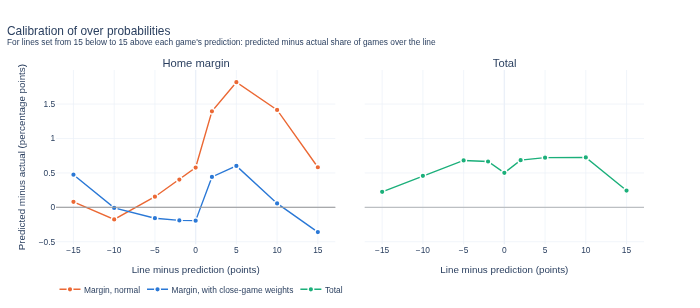

In [7]:
cal = {"Margin, normal": totals.line_calibration(
           preds.assign(margin_sd=preds["margin_resid_sd"]), "margin"),
       "Margin, with close-game weights": totals.line_calibration(preds, "margin", weights),
       "Total": totals.line_calibration(preds, "total")}
plot_line_calibration(cal).show()

In [8]:
pd.concat({name: c.set_index("offset")[["predicted", "actual"]] for name, c in cal.items()},
          axis=1).round(3)

Margin, normal        Margin, with close-game weights            Total  \
            predicted actual                       predicted actual predicted   
offset                                                                          
-15             0.877  0.876                           0.881  0.876     0.792   
-10             0.780  0.782                           0.782  0.782     0.706   
-5              0.651  0.650                           0.648  0.650     0.607   
-2              0.564  0.560                           0.558  0.560     0.543   
 0              0.504  0.498                           0.496  0.498     0.500   
 2              0.443  0.429                           0.433  0.429     0.457   
 5              0.354  0.336                           0.342  0.336     0.393   
 10             0.222  0.208                           0.208  0.208     0.294   
 15             0.123  0.117                           0.114  0.117     0.208   

               
       actual  
offset         
-15     0.789  
-10     0.701  
-5      0.600  
-2      0.537  
 0      0.495  
 2      0.450  
 5      0.386  
 10     0.287  
 15     0.206

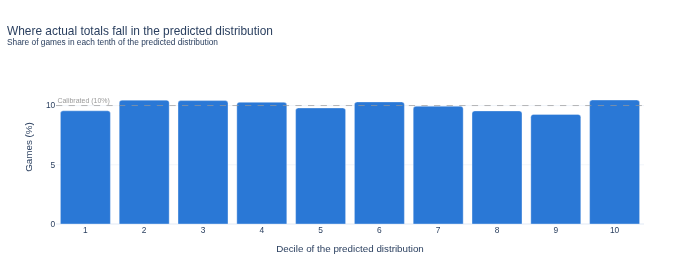

In [9]:
plot_total_pit(totals.total_pit(preds)).show()

## One game

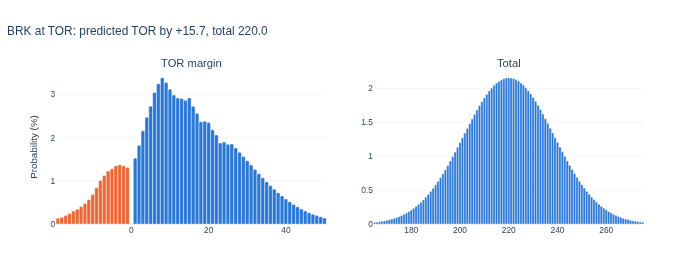

In [10]:
game = preds[preds["season"] == LAST_TEST].iloc[-1]
plot_game(game, weights[LAST_TEST]).show()